In [13]:
# Gathers Data

import csv
import math
import numpy as np

from pathlib import Path
import sys
import matplotlib.pyplot as plt
import torch
import yaml

ROOT = Path.cwd().resolve()
if not (ROOT / "data" / "dataloader.py").is_file():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data.dataloader import BallDataset, SRC_H, SRC_W
from models.baseline_cnn.model import BaselineCNN

# Trained run folder under saved_models/ (config.yaml + *.pt live here)
MODEL_DIR = "models/baseline_cnn/saved_models/baseline_cnn_train3_focal"
# Last frame of the N-frame window. The split must include that game.
SPLIT = "train"
GAME, CLIP, FRAME = "game1", "Clip1", "0010.jpg"

run_dir = Path(MODEL_DIR)
if not run_dir.is_absolute():
    run_dir = ROOT / run_dir
with (run_dir / "config.yaml").open() as f:
    cfg = yaml.safe_load(f)

dataset_path = Path(cfg["paths"]["dataset"])
if not dataset_path.is_absolute():
    cfg["paths"]["dataset"] = str((ROOT / dataset_path).resolve())

dataset = BallDataset(cfg, split=SPLIT)


def window_index(game: str, clip: str, frame: str) -> int:
    for i, (paths, _) in enumerate(dataset.samples):
        last = paths[-1]
        if last.parent.parent.name == game and last.parent.name == clip and last.name == frame:
            return i
    raise KeyError(f"{game}/{clip}/{frame} is not in the {SPLIT} split")


index = window_index(GAME, CLIP, FRAME)
sample = dataset[index]
x = sample["input"]
gt = sample["heatmap"][0]
paths, label = dataset.samples[index]
print(
    f"{SPLIT}[{index}]  {' → '.join(p.name for p in paths)}\n"
    f"input {tuple(x.shape)}  heatmap {tuple(gt.shape)}  "
    f"vis={label['visibility']}  xy=({label['x']:.0f}, {label['y']:.0f})"
)


train[5]  0005.jpg → 0006.jpg → 0007.jpg → 0008.jpg → 0009.jpg → 0010.jpg
input (18, 360, 640)  heatmap (360, 640)  vis=1  xy=(593, 278)


loaded models/baseline_cnn/saved_models/baseline_cnn_train3_focal/baseline_cnn_train3_focal.pt  cfg=baseline_cnn_train3_focal  (cuda)


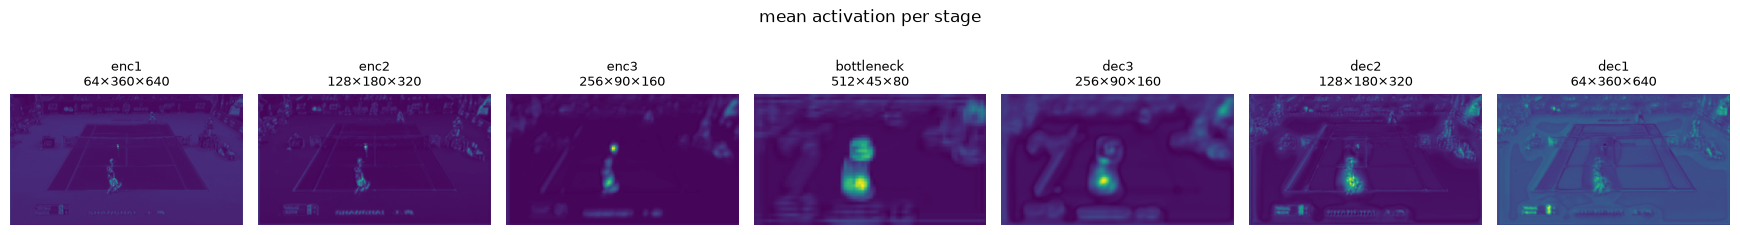

'layer = "bottleneck"\nn_channels = 8\nmaps = activations[layer][0, :n_channels].cpu().numpy()\nfig, axes = plt.subplots(1, n_channels, figsize=(2.2 * n_channels, 2.5))\nfor i, ax in enumerate(axes):\n    ax.imshow(maps[i], cmap="viridis")\n    ax.set_title(f"ch {i}", fontsize=9)\n    ax.axis("off")\nfig.suptitle(f"{layer} channels")\nfig.tight_layout()\nplt.show()'

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_cfg = cfg["model"]
model = BaselineCNN(
    num_frames=int(model_cfg["num_frames"]),
    channels_per_frame=int(model_cfg["channels_per_frame"]),
).to(device).eval()

checkpoint = next(run_dir.glob("*.pt"))
state = torch.load(checkpoint, map_location=device, weights_only=True)
model.load_state_dict(state["model"])
print(f"loaded {checkpoint.relative_to(ROOT)}  cfg={run_dir.name}  ({device})")

stages = ("enc1", "enc2", "enc3", "bottleneck", "dec3", "dec2", "dec1")
activations = {}


def capture(name):
    def hook(_module, _inputs, output):
        activations[name] = output.detach()

    return hook


handles = [getattr(model, name).register_forward_hook(capture(name)) for name in stages]
with torch.inference_mode():
    pred = model(x.unsqueeze(0).to(device))[0, 0].cpu()
for handle in handles:
    handle.remove()


fig, axes = plt.subplots(1, len(stages), figsize=(2.5 * len(stages), 2.8))
for ax, name in zip(axes, stages):
    act = activations[name][0]
    ax.imshow(act.mean(0).cpu().numpy(), cmap="viridis")
    channels, height, width = act.shape
    ax.set_title(f"{name}\n{channels}\u00d7{height}\u00d7{width}", fontsize=9)
    ax.axis("off")
fig.suptitle("mean activation per stage")
fig.tight_layout()
plt.show()

"""layer = "bottleneck"
n_channels = 8
maps = activations[layer][0, :n_channels].cpu().numpy()
fig, axes = plt.subplots(1, n_channels, figsize=(2.2 * n_channels, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(maps[i], cmap="viridis")
    ax.set_title(f"ch {i}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"{layer} channels")
fig.tight_layout()
plt.show()"""


movement  flying
obscured  False  (visible)
true xy   (593, 278)
argmax    (296, 139) on 640×360  -> (592.0, 278.0)
distance  1.0 px


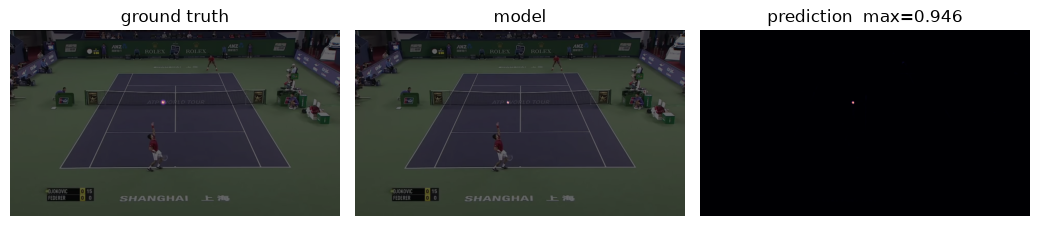

In [15]:
VISIBILITY = {0: "not in frame", 1: "visible", 2: "hard to see", 3: "occluded"}
MOVEMENT = {0: "flying", 1: "hit", 2: "bouncing"}

row = next(
    item
    for item in csv.DictReader((paths[-1].parent / "Label.csv").open(newline=""))
    if item["file name"] == paths[-1].name
)
visibility = int(row["visibility"] or 0)
status = int(row["status"] or 0)
true_x = float(row["x-coordinate"] or 0)
true_y = float(row["y-coordinate"] or 0)

heat = pred.numpy()
peak_y, peak_x = (int(i) for i in np.unravel_index(int(heat.argmax()), heat.shape))
out_h, out_w = heat.shape
pred_x = peak_x * SRC_W / out_w
pred_y = peak_y * SRC_H / out_h
distance = math.hypot(pred_x - true_x, pred_y - true_y)

print(
    f"movement  {MOVEMENT.get(status, status)}\n"
    f"obscured  {visibility == 3}  ({VISIBILITY.get(visibility, visibility)})\n"
    f"true xy   ({true_x:.0f}, {true_y:.0f})\n"
    f"argmax    ({peak_x}, {peak_y}) on {out_w}×{out_h}  -> ({pred_x:.1f}, {pred_y:.1f})\n"
    f"distance  {distance:.1f} px"
)


def show_heatmap(ax, frame, heat, title: str):
    ax.imshow(frame)
    ax.imshow(heat, cmap="magma", alpha=0.6, vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")


last_frame = x[-3:].numpy().transpose(1, 2, 0)
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
show_heatmap(axes[0], last_frame, gt.numpy(), "ground truth")
show_heatmap(axes[1], last_frame, pred.numpy(), "model")
axes[2].imshow(pred.numpy(), cmap="magma", vmin=0, vmax=1)
axes[2].set_title(f"prediction  max={float(pred.max()):.3f}")
axes[2].axis("off")
fig.tight_layout()
plt.show()


In [16]:
import torch.nn.functional as F
from torch.utils.data import DataLoader

test_ds = BallDataset(cfg, split="test")
n = len(test_ds)

clip_status = {}
visibility = np.empty(n, np.int8)
movement = np.empty(n, np.int8)
true_xy = np.empty((n, 2), np.float32)
for i, (window, lb) in enumerate(test_ds.samples):
    clip = window[-1].parent
    table = clip_status.get(clip)
    if table is None:
        table = {}
        with (clip / "Label.csv").open(newline="") as f:
            for item in csv.DictReader(f):
                table[item["file name"]] = int(item["status"] or 0)
        clip_status[clip] = table
    visibility[i] = int(lb["visibility"])
    movement[i] = table.get(window[-1].name, 0)
    true_xy[i] = (lb["x"], lb["y"])

losses = np.empty(n, np.float64)
dists = np.empty(n, np.float64)
confs = np.empty(n, np.float64)

loader = DataLoader(
    test_ds,
    batch_size=int(cfg["train"]["batch_size"]),
    shuffle=False,
    num_workers=int(cfg["train"].get("num_workers", 0)),
)

model.eval()
offset = 0
with torch.inference_mode():
    for batch in loader:
        inp = batch["input"].to(device)
        target = batch["heatmap"].to(device)
        out = model(inp)
        bsz, _, height, width = out.shape
        losses[offset : offset + bsz] = (
            F.mse_loss(out, target, reduction="none").mean(dim=(1, 2, 3)).cpu().numpy()
        )
        confs[offset : offset + bsz] = out.amax(dim=(1, 2, 3)).cpu().numpy()
        index = out.view(bsz, -1).argmax(dim=1)
        peak_x = (index % width).float() * (SRC_W / width)
        peak_y = torch.div(index, width, rounding_mode="floor").float() * (SRC_H / height)
        xy = torch.as_tensor(true_xy[offset : offset + bsz], device=device)
        dists[offset : offset + bsz] = torch.hypot(peak_x - xy[:, 0], peak_y - xy[:, 1]).cpu().numpy()
        offset += bsz


def show_group(name, mask):
    count = int(mask.sum())
    if count == 0:
        return
    print(
        f"{name:16}  n={count:5d}  "
        f"loss={losses[mask].mean():.6f}  "
        f"dist={dists[mask].mean():6.1f}  "
        f"conf={confs[mask].mean():.3f}"
    )


print(f"test  n={n}  dist in source px  conf = heatmap peak")
show_group("all", np.ones(n, dtype=bool))
print("movement")
for code, name in MOVEMENT.items():
    show_group(f"  {name}", movement == code)
print("obscurity")
for code, name in VISIBILITY.items():
    show_group(f"  {name}", visibility == code)


test  n=2084  dist in source px  conf = heatmap peak
all               n= 2084  loss=0.000044  dist=  37.3  conf=0.779
movement
  flying          n= 1983  loss=0.000043  dist=  37.0  conf=0.787
  hit             n=   48  loss=0.000068  dist=  77.9  conf=0.398
  bouncing        n=   53  loss=0.000046  dist=  11.7  conf=0.800
obscurity
  not in frame    n=   62  loss=0.000003  dist= 526.1  conf=0.130
  visible         n= 1844  loss=0.000044  dist=  12.6  conf=0.826
  hard to see     n=  177  loss=0.000061  dist= 122.9  conf=0.521
  occluded        n=    1  loss=0.000085  dist=  61.1  conf=0.024


In [ ]:
test  n=2084  dist in source px  conf = heatmap peak
all               n= 2084  loss=0.000034  dist=  65.9  conf=0.561
movement
  flying          n= 1983  loss=0.000033  dist=  63.7  conf=0.572
  hit             n=   48  loss=0.000082  dist= 184.7  conf=0.053
  bouncing        n=   53  loss=0.000030  dist=  41.9  conf=0.617
obscurity
  not in frame    n=   62  loss=0.000000  dist= 937.6  conf=0.005
  visible         n= 1844  loss=0.000032  dist=  27.1  conf=0.607
  hard to see     n=  177  loss=0.000060  dist= 165.4  conf=0.289
  occluded        n=    1  loss=0.000085  dist=  29.7  conf=0.005

In [ ]:
test  n=2120  dist in source px  conf = heatmap peak
all               n= 2120  loss=0.000024  dist=  34.4  conf=0.644
movement
  flying          n= 2015  loss=0.000023  dist=  34.1  conf=0.654
  hit             n=   48  loss=0.000064  dist=  80.3  conf=0.227
  bouncing        n=   57  loss=0.000026  dist=   5.6  conf=0.627
obscurity
  not in frame    n=   62  loss=0.000000  dist= 678.9  conf=0.005
  visible         n= 1875  loss=0.000022  dist=   8.7  conf=0.694
  hard to see     n=  182  loss=0.000054  dist=  77.4  conf=0.340
  occluded        n=    1  loss=0.000085  dist= 424.4  conf=0.003